# BIOT 6900 · Module 10 — Medical Imaging AI
## Real-data notebook: transfer learning on pathology, and interrogating the model

*Week 10 · Part III · run-and-read*

The toy made everything easy on purpose. This notebook removes the training wheels. Two things change, and they change everything:

| | Toy (MedNIST) | **Real (this notebook)** |
|---|---|---|
| Data | plentiful, easy | **scarce, messy** real H&E tiles |
| Model | tiny CNN from scratch | **pretrained DenseNet121, fine-tuned** |
| Confounder | a white square you planted | a **realistic pen/ink mark** |

The task is the one the whole module opened on: **malignant epithelium vs. normal mucosa** — a patch-level "is this tumour?" call.

You will:
1. See why **transfer learning** beats training from scratch *when data is scarce* — a quick head-to-head.
2. Fine-tune a pretrained **DenseNet121** on real colorectal histopathology.
3. Run **Grad-CAM** on it — with the colour-scale fix from the toy (see the note in §5).
4. Break it with a realistic artifact and catch the failure with **Grad-CAM + a hand-built occlusion test** — two methods, because you never trust one.

> **Compute:** defaults finish on a **laptop CPU** in roughly 5–10 minutes (600 training tiles, 128 px, 3 epochs × 3 models). A GPU makes it faster. The first run also downloads the ImageNet DenseNet121 weights (~30 MB).
>
> **Data:** if your instructor gave you `pathmnist_tumour_vs_normal_subset.npz`, put it in a `data/` folder next to this notebook and **no dataset download is needed**. Otherwise §1 downloads PathMNIST once (~1.1 GB at the default 64 px) and saves the small subset for next time.

## 0 · Setup

In [1]:
# !pip install -q "monai[pillow]" "medmnist>=3.0" torch torchvision scikit-learn matplotlib

import os, numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fnn

import monai
from monai.utils import set_determinism
from monai.networks.nets import DenseNet121
from monai.visualize import GradCAM

print("MONAI:", monai.__version__, "| torch:", torch.__version__)

SEED = 0
set_determinism(seed=SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "(a GPU is recommended but not required)")

/opt/anaconda3/envs/biot6900/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


MONAI: 1.6.1 | torch: 2.15.0
device: cpu (a GPU is recommended but not required)


## 1 · The data: real colorectal histopathology (PathMNIST)

**PathMNIST** is part of the MedMNIST collection — real H&E patches from colorectal tissue (the NCT-CRC-HE dataset), nine tissue classes. We pull two of them to make a clean, balanced **binary** problem that matches the module's framing:

- **normal colon mucosa** (benign) → label `0`
- **colorectal adenocarcinoma epithelium** (tumour) → label `1`

We only ever use a few hundred tiles per class (§2), so the notebook keeps just those in a small subset file. If that file is present, nothing is downloaded.

These are *real* tiles. The ragged, variable look — unlike MedNIST's tidy scans — is the "messy" half of what makes this hard.

In [2]:
from medmnist import PathMNIST, INFO

IMG_SIZE = 128        # size the model sees (GPU: try 224 — matches ImageNet pretraining, sharper Grad-CAM)
SUBSET_FILE = "./data/pathmnist_tumour_vs_normal_subset.npz"   # small prepared file (~60 MB), if you have it
DL_SIZE = 64          # only used if SUBSET_FILE is missing. PathMNIST download sizes:
                      #   28 px ~0.2 GB | 64 px ~1.1 GB | 128 px ~4.3 GB  (tiles are resized to IMG_SIZE either way)

print("PathMNIST classes:")
for k, v in INFO["pathmnist"]["label"].items():
    print(f"  {k}: {v}")

NORMAL, TUMOR = 6, 8                 # class ids in PathMNIST
class_names = ["normal", "tumour"]

def to_binary(x, y):
    keep = np.isin(y, [NORMAL, TUMOR])
    x, y = x[keep], y[keep]
    yb = (y == TUMOR).astype(np.int64)   # 1 = tumour, 0 = normal
    return x, yb

FROM_SUBSET = os.path.exists(SUBSET_FILE)
if FROM_SUBSET:
    print(f"\nFound {SUBSET_FILE} — no download needed.")
else:
    # medmnist returns images as HxWx3 uint8 and labels as (N,1)
    def load_split(split):
        ds = PathMNIST(split=split, download=True, size=DL_SIZE)
        return ds.imgs, ds.labels.squeeze()
    xtr, ytr = to_binary(*load_split("train"))
    xva, yva = to_binary(*load_split("val"))
    xte, yte = to_binary(*load_split("test"))
    print(f"\nbinary pools -> train {len(ytr)} | val {len(yva)} | test {len(yte)}")

PathMNIST classes:
  0: adipose
  1: background
  2: debris
  3: lymphocytes
  4: mucus
  5: smooth muscle
  6: normal colon mucosa
  7: cancer-associated stroma
  8: colorectal adenocarcinoma epithelium

Found ./data/pathmnist_tumour_vs_normal_subset.npz — no download needed.


## 2 · Work in the scarce-data regime (on purpose)

Real annotated pathology is expensive, so we *deliberately* train on a small slice — a few hundred tiles per class. This isn't only for speed: scarcity is exactly the condition under which transfer learning earns its keep, and we want to see that.

In [3]:
N_PER_CLASS = 300    # GPU: raise to 1500+ for cleaner accuracy (delete SUBSET_FILE first so it is rebuilt)
rng = np.random.default_rng(SEED)

def subsample(x, y, n_per_class):
    idx = []
    for c in (0, 1):
        ci = np.where(y == c)[0]
        idx.append(rng.permutation(ci)[:n_per_class])
    idx = rng.permutation(np.concatenate(idx))
    return x[idx], y[idx]

if FROM_SUBSET:
    d = np.load(SUBSET_FILE)
    xtr_s, ytr_s, xva_s, yva_s, xte_s, yte_s = (d[k] for k in
        ["xtr", "ytr", "xva", "yva", "xte", "yte"])
    print(f"subset tiles are {xtr_s.shape[1]} px (resized to {IMG_SIZE} px below)")
else:
    xtr_s, ytr_s = subsample(xtr, ytr, N_PER_CLASS)
    xva_s, yva_s = subsample(xva, yva, min(200, (yva == 0).sum(), (yva == 1).sum()))
    xte_s, yte_s = subsample(xte, yte, min(300, (yte == 0).sum(), (yte == 1).sum()))
    os.makedirs(os.path.dirname(SUBSET_FILE), exist_ok=True)
    np.savez_compressed(SUBSET_FILE, xtr=xtr_s, ytr=ytr_s, xva=xva_s, yva=yva_s, xte=xte_s, yte=yte_s)
    del xtr, ytr, xva, yva, xte, yte          # free the large pools
    print(f"saved the subset to {SUBSET_FILE} — the next run skips the download")
print(f"using -> train {len(ytr_s)} | val {len(yva_s)} | test {len(yte_s)}")

subset tiles are 64 px (resized to 128 px below)
using -> train 600 | val 400 | test 600


## 3 · Look at the tiles

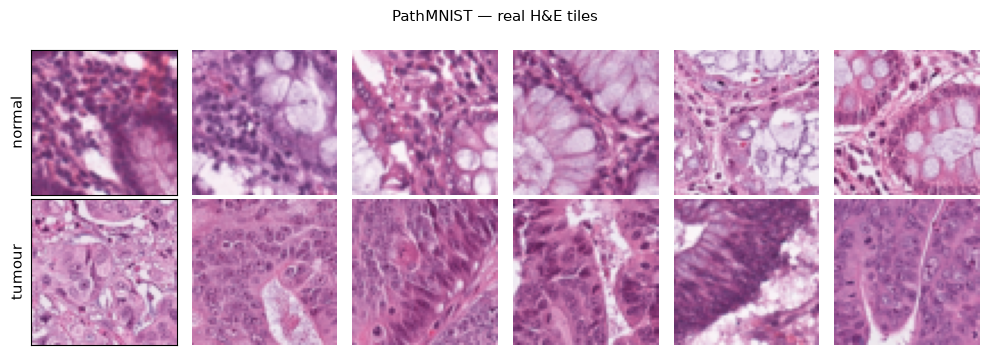

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for r, c in enumerate((0, 1)):
    ci = np.where(ytr_s == c)[0][:6]
    for k, j in enumerate(ci):
        axes[r, k].imshow(xtr_s[j]); axes[r, k].axis("off")
    axes[r, 0].set_ylabel(class_names[c], fontsize=11, rotation=90)
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
plt.suptitle("PathMNIST — real H&E tiles", fontsize=11); plt.tight_layout(); plt.show()

## 4 · Preprocessing and a Dataset

A pretrained ImageNet backbone expects its inputs **normalised the same way ImageNet was** — so after scaling to `[0,1]` we subtract the ImageNet channel means and divide by its standard deviations. Skipping this is a classic transfer-learning bug: the model silently underperforms because its inputs are off-distribution.

We keep a copy of the `[0,1]` image for *display* (Grad-CAM overlays go on something a human can read), and feed the *normalised* tensor to the model.

In [5]:
from torch.utils.data import Dataset, DataLoader
from monai.transforms import Compose, EnsureChannelFirst, ScaleIntensity, Resize, EnsureType

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# array -> (3, IMG_SIZE, IMG_SIZE) float in [0,1]
to01 = Compose([
    EnsureChannelFirst(channel_dim=-1),   # HxWx3 -> 3xHxW
    ScaleIntensity(),                      # -> [0,1]
    Resize((IMG_SIZE, IMG_SIZE)),
    EnsureType(data_type="tensor"),
])

def normalize(x01):
    return (x01 - IMAGENET_MEAN) / IMAGENET_STD

class TileDataset(Dataset):
    def __init__(self, imgs, labels, artifact_label=None):
        self.imgs, self.labels = imgs, labels
        self.artifact_label = artifact_label     # inject ink-mark artifact into this class (confounder demo)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        x01 = to01(self.imgs[i])

        if self.artifact_label is not None and int(self.labels[i]) == self.artifact_label:
            x01 = add_scanner_patch(x01)

        return normalize(x01), int(self.labels[i])

def make_loaders(artifact_label=None, bs=32):
    # The artifact (if any) goes into training AND validation tiles — just as a real
    # site-specific artifact would be present throughout one site's data.
    tr = DataLoader(TileDataset(xtr_s, ytr_s, artifact_label), batch_size=bs, shuffle=True)
    va = DataLoader(TileDataset(xva_s, yva_s, artifact_label), batch_size=64)
    return tr, va

# quick shape/range sanity check
_x01 = to01(xtr_s[0]); _xn = normalize(_x01)
print("display [0,1]:", tuple(_x01.shape), float(_x01.min()), float(_x01.max()))
print("model input  :", tuple(_xn.shape), f"mean~{float(_xn.mean()):.2f}")

display [0,1]: (3, 128, 128) 0.0 1.0
model input  : (3, 128, 128) mean~0.06


## 5 · Scratch vs. transfer — the head-to-head

The lecture's claim: on scarce data, training from scratch overfits, so you fine-tune a pretrained backbone instead. Let's not take it on faith. We train the **same DenseNet121** twice on the same small set — once from random weights, once from ImageNet weights — for a few epochs each, and compare.

> **Grad-CAM: two settings carried over from the toy.**
> 1. **Target layer.** We point Grad-CAM at `class_layers.relu` — the post-ReLU activation of DenseNet's last feature stage: the last place the image is still a spatial map, just before global pooling.
> 2. **Colour scale.** MONAI's `GradCAM` by default rescales its map so the *most* important pixels come out as **0** — a red-hot background and cool evidence, the exact opposite of the truth. Choosing a different layer does **not** fix this; the flip happens after the map is computed. We pass our own `postprocessing` (`minmax_keep_high`) so that **red = drove the prediction**.

In [6]:
def build_densenet(pretrained):
    return DenseNet121(spatial_dims=2, in_channels=3, out_channels=2,
                       pretrained=pretrained).to(device)

TARGET_LAYER = "class_layers.relu"   # last spatial feature map, just before global pooling

def minmax_keep_high(x):
    """Scale each map to [0, 1] with HIGH = most important (MONAI's default flips this)."""
    flat = x.flatten(start_dim=1)
    lo = flat.min(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    hi = flat.max(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    return (x - lo) / (hi - lo + 1e-8)

def make_cam(net):
    return GradCAM(nn_module=net, target_layers=TARGET_LAYER, postprocessing=minmax_keep_high)

def run_epoch(net, loader, opt=None):
    train = opt is not None
    net.train() if train else net.eval()
    crit = nn.CrossEntropyLoss(); tot = cor = 0; ls = 0.0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = net(x); loss = crit(out, y)
            if train: opt.zero_grad(); loss.backward(); opt.step()
            ls += loss.item() * x.size(0); cor += (out.argmax(1) == y).sum().item(); tot += x.size(0)
    return ls / tot, cor / tot

def train(net, tr_loader, va_loader, epochs=3, lr=1e-4):
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for ep in range(1, epochs + 1):
        trl, tra = run_epoch(net, tr_loader, opt)
        val, vaa = run_epoch(net, va_loader)
        print(f"  epoch {ep}: train acc {tra:.3f} | val acc {vaa:.3f}")
    return net

EPOCHS = 3
tr_loader, va_loader = make_loaders()

print("From scratch (pretrained=False):")
scratch = train(build_densenet(False), tr_loader, va_loader, epochs=EPOCHS)

print("\nTransfer (pretrained=True):")
model = train(build_densenet(True), tr_loader, va_loader, epochs=EPOCHS)
print("\n-> transfer should lead, and lead by more the scarcer the data.")

From scratch (pretrained=False):
  epoch 1: train acc 0.808 | val acc 0.843
  epoch 2: train acc 0.918 | val acc 0.917
  epoch 3: train acc 0.938 | val acc 0.905

Transfer (pretrained=True):
  epoch 1: train acc 0.857 | val acc 0.945
  epoch 2: train acc 0.993 | val acc 0.965
  epoch 3: train acc 1.000 | val acc 0.958

-> transfer should lead, and lead by more the scarcer the data.


## 6 · Evaluate the transfer model

test accuracy: 0.930


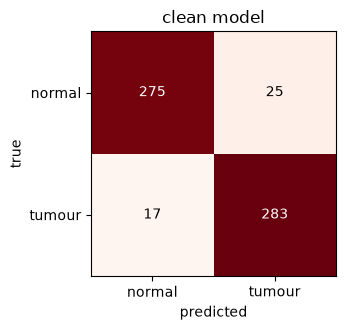

Clean validation accuracy: 0.958
Clean test accuracy: 0.930


In [7]:
from sklearn.metrics import confusion_matrix

def evaluate(net, imgs, labels):
    net.eval(); preds = []
    loader = DataLoader(TileDataset(imgs, labels), batch_size=64)
    with torch.no_grad():
        for x, _ in loader:
            preds.append(net(x.to(device)).argmax(1).cpu().numpy())
    preds = np.concatenate(preds)
    return preds, (preds == labels).mean()

pred, acc = evaluate(model, xte_s, yte_s)
print(f"test accuracy: {acc:.3f}")
cm = confusion_matrix(yte_s, pred)
fig, ax = plt.subplots(figsize=(3.8, 3.4)); ax.imshow(cm, cmap="Reds")
ax.set_xticks([0,1]); ax.set_xticklabels(class_names); ax.set_yticks([0,1]); ax.set_yticklabels(class_names)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i,j], ha="center", va="center", color="white" if cm[i,j] > cm.max()/2 else "black")
plt.title("clean model"); plt.tight_layout(); plt.show()

_, clean_val_acc = evaluate(model, xva_s, yva_s)
_, clean_test_acc = evaluate(model, xte_s, yte_s)

print(f"Clean validation accuracy: {clean_val_acc:.3f}")
print(f"Clean test accuracy: {clean_test_acc:.3f}")

## 7 · Grad-CAM on the clean model

Colour key (jet): **red = drove the prediction**, **blue = ignored**.

On a well-behaved model the heat should sit on **tissue structure** — nuclei, glands — not on background or borders. This is the "trustworthy 0.97" case from the lecture.

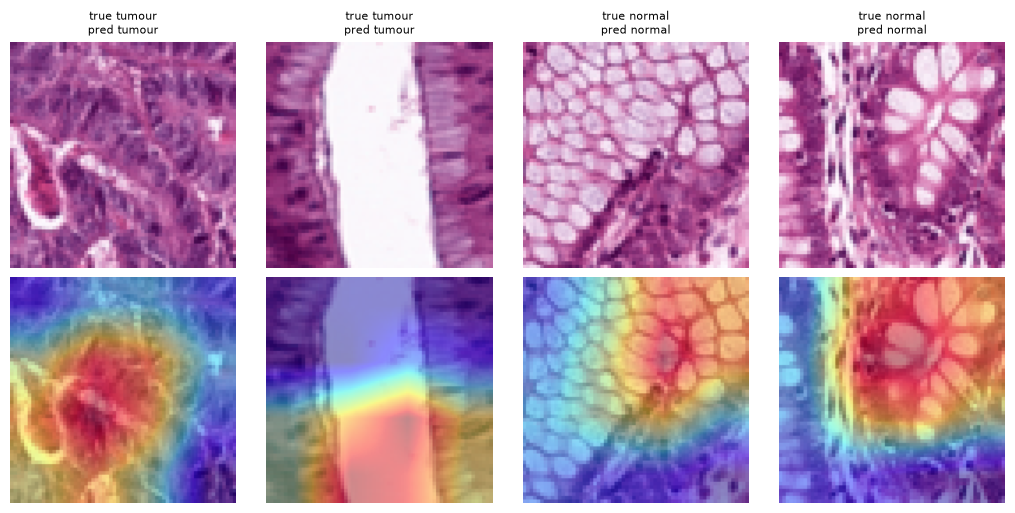

In [8]:
cam = make_cam(model)

def show_cam(net, cam_obj, imgs, labels, idxs):
    net.eval(); k = len(idxs)
    fig, ax = plt.subplots(2, k, figsize=(2.6*k, 5.2))
    for col, j in enumerate(idxs):
        x01 = to01(imgs[j]); xin = normalize(x01).unsqueeze(0).to(device)
        pr = int(net(xin).argmax(1).item())
        heat = cam_obj(x=xin, class_idx=pr).squeeze().detach().cpu().numpy()
        disp = x01.permute(1,2,0).cpu().numpy()
        ax[0,col].imshow(disp); ax[0,col].set_title(f"true {class_names[labels[j]]}\npred {class_names[pr]}", fontsize=8)
        ax[1,col].imshow(disp); ax[1,col].imshow(heat, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[0,col].axis("off"); ax[1,col].axis("off")
    plt.tight_layout(); plt.show()

tum = np.where(yte_s == 1)[0][:2]
normal = np.where(yte_s == 0)[0][:2]

sample_idxs = list(tum) + list(normal)
show_cam(model, cam, xte_s, yte_s, sample_idxs)

## 8 · Design a new confounder: scanner calibration patch

I simulated a small, fixed-position calibration patch that could arise from a scanner overlay or image acquisition workflow. Such a patch would not represent tissue morphology, but could become correlated with a diagnostic class if images from different acquisition pipelines were unevenly distributed across classes.

A synthetic amber-colored patch was added only to tumour tiles in both training and validation sets. The clean model was trained without this artifact and retained as an independent control.

The patch is deliberately synthetic. Its purpose is to test whether the classifier learns a non-biological shortcut rather than relying on histological features.

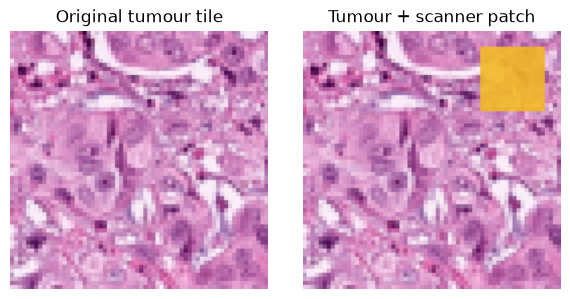

Artifact area: 6.2%


In [9]:
# Part C: Synthetic scanner calibration patch

ARTIFACT_LABEL = 1  # tumour

PATCH_SIZE = 32
PATCH_RGB = (0.95, 0.72, 0.15)  # amber calibration-like patch
PATCH_ALPHA = 0.90

# Fixed position near the upper-right corner
PATCH_MASK = torch.zeros((IMG_SIZE, IMG_SIZE), dtype=torch.bool)

top = 8
left = IMG_SIZE - PATCH_SIZE - 8

PATCH_MASK[
    top:top + PATCH_SIZE,
    left:left + PATCH_SIZE
] = True

def add_scanner_patch(x01):
    """Add a synthetic, non-biological scanner patch to a [0,1] image."""
    out = x01.clone()

    patch_color = torch.tensor(
        PATCH_RGB,
        dtype=out.dtype,
        device=out.device
    ).view(3, 1)

    mask = PATCH_MASK.to(out.device)

    out[:, mask] = (
        (1 - PATCH_ALPHA) * out[:, mask]
        + PATCH_ALPHA * patch_color
    )

    return out.clamp(0, 1)


# Visualize clean vs. artifact-injected tumour tile
j = int(np.where(ytr_s == 1)[0][0])

clean = to01(xtr_s[j])
dirty = add_scanner_patch(clean)

fig, ax = plt.subplots(1, 2, figsize=(6, 3))

ax[0].imshow(clean.permute(1, 2, 0).numpy())
ax[0].set_title("Original tumour tile")

ax[1].imshow(dirty.permute(1, 2, 0).numpy())
ax[1].set_title("Tumour + scanner patch")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

print(f"Artifact area: {PATCH_MASK.float().mean():.1%}")

In [10]:
# Train the confounded model with the scanner patch
# injected into tumour tiles in both train and validation.

set_determinism(seed=SEED)

tr_cf, va_cf = make_loaders(
    artifact_label=ARTIFACT_LABEL
)

print("Training confounded model with scanner patch:")

model_cf = train(
    build_densenet(True),
    tr_cf,
    va_cf,
    epochs=EPOCHS
)

# Validation accuracy on the confounded validation set
_, confounded_val_acc = run_epoch(model_cf, va_cf)

print(f"Confounded validation accuracy: {confounded_val_acc:.3f}")

Training confounded model with scanner patch:
  epoch 1: train acc 0.882 | val acc 0.995
  epoch 2: train acc 1.000 | val acc 0.998
  epoch 3: train acc 1.000 | val acc 1.000
Confounded validation accuracy: 1.000


The confounded model was trained on tumour images containing the synthetic scanner patch. Its validation accuracy must be interpreted cautiously because the same class-associated artifact is present in both training and validation data.

High validation accuracy alone does not demonstrate that the model learned tumour morphology. The following tests examine whether predictions depend on the artificial patch.

## 9 · Test whether the scanner patch was learned

Three complementary tests are used:

1. **Grad-CAM:** Does the confounded model concentrate attention on the scanner patch?
2. **Reliance test:** Does tumour recall decrease when the patch is removed?
3. **Flip test with a clean control:** Does adding the patch to normal images cause the confounded model to predict tumour more often than the clean model?

The clean model was never trained on the scanner patch, so differences between the two models provide evidence of artifact-specific shortcut learning.

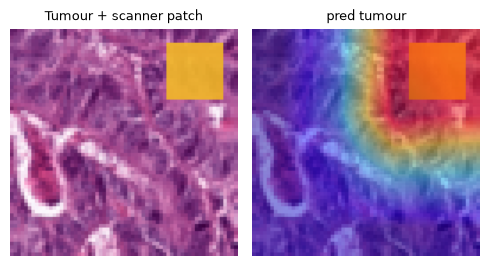

(1,
 array([[0.        , 0.        , 0.        , ..., 0.86749417, 0.86749417,
         0.86749417],
        [0.        , 0.        , 0.        , ..., 0.86749417, 0.86749417,
         0.86749417],
        [0.        , 0.        , 0.        , ..., 0.86749417, 0.86749417,
         0.86749417],
        ...,
        [0.05805163, 0.05805163, 0.05805163, ..., 0.05470955, 0.05470955,
         0.05470955],
        [0.05805163, 0.05805163, 0.05805163, ..., 0.05470955, 0.05470955,
         0.05470955],
        [0.05805163, 0.05805163, 0.05805163, ..., 0.05470955, 0.05470955,
         0.05470955]], shape=(128, 128), dtype=float32))

In [11]:
cam_cf = make_cam(model_cf)

# (1) Grad-CAM on a tumour tile WITH the ink: heat should move to the mark
def cam_on_array(net, cam_obj, x01, title):
    xin = normalize(x01).unsqueeze(0).to(device)
    pr = int(net(xin).argmax(1).item())
    heat = cam_obj(x=xin, class_idx=pr).squeeze().detach().cpu().numpy()
    disp = x01.permute(1,2,0).cpu().numpy()
    fig, ax = plt.subplots(1, 2, figsize=(5, 2.7))
    ax[0].imshow(disp); ax[0].set_title(title, fontsize=9)
    ax[1].imshow(disp); ax[1].imshow(heat, cmap="jet", alpha=0.45, vmin=0, vmax=1); ax[1].set_title(f"pred {class_names[pr]}", fontsize=9)
    ax[0].axis("off"); ax[1].axis("off"); plt.tight_layout(); plt.show()
    return pr, heat

jt = int(np.where(yte_s == 1)[0][0])

x_tumour_patch = add_scanner_patch(to01(xte_s[jt]))

cam_on_array(
    model_cf,
    cam_cf,
    x_tumour_patch,
    "Tumour + scanner patch"
)

In [12]:
# Part D: Reliance test

def tumour_acc(net, with_artifact):
    net.eval()
    ti = np.where(yte_s == 1)[0]
    correct = 0

    with torch.no_grad():
        for j in ti:
            x01 = to01(xte_s[j])

            if with_artifact:
                x01 = add_scanner_patch(x01)

            xin = normalize(x01).unsqueeze(0).to(device)
            pred = int(net(xin).argmax(1).item())

            correct += (pred == 1)

    return correct / len(ti)


# Confounded model
cf_with = tumour_acc(model_cf, True)
cf_without = tumour_acc(model_cf, False)

# Clean control
clean_with = tumour_acc(model, True)
clean_without = tumour_acc(model, False)

print("TUMOUR RECALL")
print(f"Confounded model WITH patch   : {cf_with:.3f}")
print(f"Confounded model WITHOUT patch: {cf_without:.3f}")
print(f"Clean model WITH patch        : {clean_with:.3f}")
print(f"Clean model WITHOUT patch     : {clean_without:.3f}")

print("\nRecall change when patch is removed:")
print(f"Confounded: {cf_with - cf_without:+.3f}")
print(f"Clean:      {clean_with - clean_without:+.3f}")

TUMOUR RECALL
Confounded model WITH patch   : 0.997
Confounded model WITHOUT patch: 0.393
Clean model WITH patch        : 0.957
Clean model WITHOUT patch     : 0.943

Recall change when patch is removed:
Confounded: +0.603
Clean:      +0.013


In [13]:
# Part D: Flip test with clean control

def normal_artifact_test(net):
    net.eval()

    ni = np.where(yte_s == 0)[0]
    predictions_before = []
    predictions_after = []

    with torch.no_grad():
        for j in ni:
            x_clean = to01(xte_s[j])
            x_patch = add_scanner_patch(x_clean)

            p_before = int(
                net(normalize(x_clean).unsqueeze(0).to(device))
                .argmax(1).item()
            )

            p_after = int(
                net(normalize(x_patch).unsqueeze(0).to(device))
                .argmax(1).item()
            )

            predictions_before.append(p_before)
            predictions_after.append(p_after)

    before = np.array(predictions_before)
    after = np.array(predictions_after)

    # Fraction of normal tiles whose prediction changes
    flip_rate = np.mean(before != after)

    # Fraction specifically changing from normal to tumour
    normal_to_tumour = np.mean((before == 0) & (after == 1))

    # Fraction classified as tumour after patch addition
    tumour_call_rate = np.mean(after == 1)

    return flip_rate, normal_to_tumour, tumour_call_rate


clean_flip, clean_n2t, clean_tumour_call = normal_artifact_test(model)
cf_flip, cf_n2t, cf_tumour_call = normal_artifact_test(model_cf)

print("NORMAL TILE ARTIFACT TEST")
print(f"Number of normal test tiles: {(yte_s == 0).sum()}")

print("\nClean model:")
print(f"  Prediction flip rate: {clean_flip:.1%}")
print(f"  Normal -> tumour:     {clean_n2t:.1%}")
print(f"  Tumour calls after:   {clean_tumour_call:.1%}")

print("\nConfounded model:")
print(f"  Prediction flip rate: {cf_flip:.1%}")
print(f"  Normal -> tumour:     {cf_n2t:.1%}")
print(f"  Tumour calls after:   {cf_tumour_call:.1%}")

print("\nControl gap (normal -> tumour):")
print(f"{cf_n2t - clean_n2t:+.1%}")

NORMAL TILE ARTIFACT TEST
Number of normal test tiles: 300

Clean model:
  Prediction flip rate: 4.0%
  Normal -> tumour:     2.7%
  Tumour calls after:   9.7%

Confounded model:
  Prediction flip rate: 84.7%
  Normal -> tumour:     84.7%
  Tumour calls after:   85.0%

Control gap (normal -> tumour):
+82.0%


The reliance and flip tests were compared against the clean model. Evidence of shortcut learning would include a larger reduction in tumour recall after artifact removal and a higher normal-to-tumour flip rate in the confounded model than in the clean control.

If both models respond similarly to the patch, the artifact-specific shortcut hypothesis is not supported by this comparison. The results must be interpreted using the observed values rather than validation accuracy alone.

## 10 · A second opinion: occlusion sensitivity (built by hand)

Never trust a single saliency method. **Occlusion sensitivity** is a completely different idea from Grad-CAM: slide a grey patch across the image and watch how much the predicted-class probability **drops**. Where hiding the pixels hurts the most is where the evidence lived.

MONAI ships `OcclusionSensitivity`, but we build it in a few lines so the mechanism is visible — and so it agrees with Grad-CAM for the *right* reason. On the confounded model, the biggest drop should be at the **ink mark**. Rather than eyeball the two maps, we then *measure* how much of each one's evidence falls on the mark — and only claim agreement if the numbers agree.

CLEAN MODEL: tumour tile


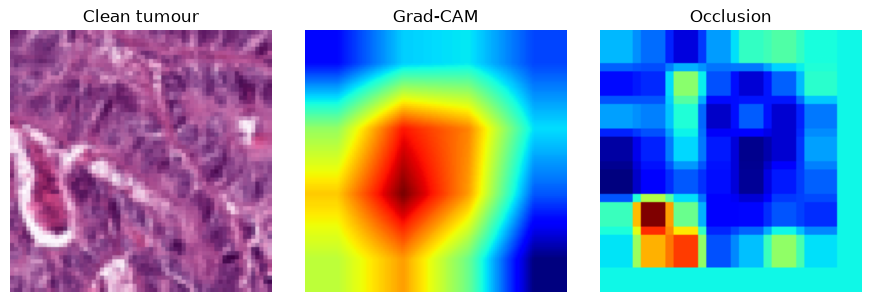

CLEAN MODEL: normal tile


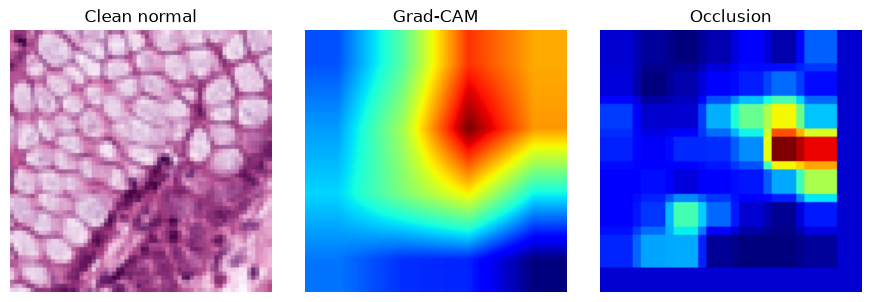

CONFOUNDED MODEL: tumour + scanner patch


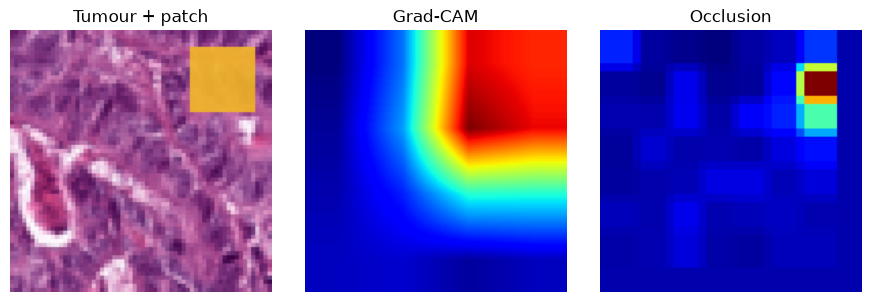

CLEAN CONTROL: tumour + scanner patch


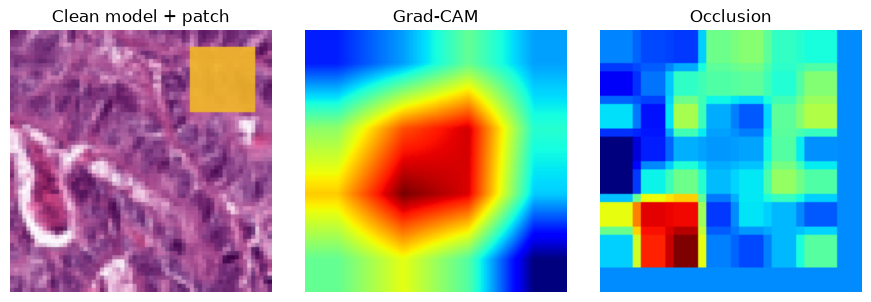


ARTIFACT ATTENTION ANALYSIS
Artifact area: 6.2%

Confounded model:
  Grad-CAM share:  16.5%
  Occlusion share: 52.3%

Clean control:
  Grad-CAM share:  4.7%
  Occlusion share: 9.1%

Confounded minus clean:
  Grad-CAM difference:  +11.8%
  Occlusion difference: +43.2%


In [14]:
# Part B and D: Occlusion sensitivity + Grad-CAM

def occlusion_map(net, x01, target, patch=20, stride=16, baseline=0.0):
    net.eval()

    xin = normalize(x01).unsqueeze(0).to(device)

    with torch.no_grad():
        base = Fnn.softmax(net(xin), dim=1)[0, target].item()

    H, W = IMG_SIZE, IMG_SIZE
    heat = np.zeros((H, W))
    cnt = np.zeros((H, W))

    for i in range(0, H - patch + 1, stride):
        for j in range(0, W - patch + 1, stride):
            x2 = xin.clone()
            x2[..., i:i+patch, j:j+patch] = baseline

            with torch.no_grad():
                p = Fnn.softmax(net(x2), dim=1)[0, target].item()

            heat[i:i+patch, j:j+patch] += base - p
            cnt[i:i+patch, j:j+patch] += 1

    return heat / np.maximum(cnt, 1)


def compare_explanations(net, cam_obj, x01, target, title):
    xin = normalize(x01).unsqueeze(0).to(device)

    gmap = cam_obj(
        x=xin,
        class_idx=target
    ).squeeze().detach().cpu().numpy()

    omap = occlusion_map(net, x01, target=target)

    disp = x01.permute(1, 2, 0).cpu().numpy()

    fig, ax = plt.subplots(1, 3, figsize=(9, 3))

    ax[0].imshow(disp)
    ax[0].set_title(title)

    ax[1].imshow(gmap, cmap="jet", vmin=0, vmax=1)
    ax[1].set_title("Grad-CAM")

    ax[2].imshow(omap, cmap="jet")
    ax[2].set_title("Occlusion")

    for a in ax:
        a.axis("off")

    plt.tight_layout()
    plt.show()

    return gmap, omap


# ------------------------------------------
# Part B: Clean model on clean tissue
# ------------------------------------------

cam_clean = make_cam(model)

jt = int(np.where(yte_s == 1)[0][0])
jn = int(np.where(yte_s == 0)[0][0])

print("CLEAN MODEL: tumour tile")

clean_tumour_g, clean_tumour_o = compare_explanations(
    model,
    cam_clean,
    to01(xte_s[jt]),
    target=1,
    title="Clean tumour"
)

print("CLEAN MODEL: normal tile")

clean_normal_g, clean_normal_o = compare_explanations(
    model,
    cam_clean,
    to01(xte_s[jn]),
    target=0,
    title="Clean normal"
)


# ------------------------------------------
# Part D: Confounded model on artifact tile
# ------------------------------------------

x_artifact = add_scanner_patch(to01(xte_s[jt]))

print("CONFOUNDED MODEL: tumour + scanner patch")

cf_gmap, cf_omap = compare_explanations(
    model_cf,
    cam_cf,
    x_artifact,
    target=1,
    title="Tumour + patch"
)


# ------------------------------------------
# Clean control: same artifact tile
# ------------------------------------------

print("CLEAN CONTROL: tumour + scanner patch")

ctrl_gmap, ctrl_omap = compare_explanations(
    model,
    cam_clean,
    x_artifact,
    target=1,
    title="Clean model + patch"
)


# ------------------------------------------
# Quantify attention on the artifact
# ------------------------------------------

mask = PATCH_MASK.cpu().numpy()

def artifact_share(m):
    m = np.clip(m, 0, None)
    return m[mask].sum() / (m.sum() + 1e-8)


cf_gshare = artifact_share(cf_gmap)
cf_oshare = artifact_share(cf_omap)

ctrl_gshare = artifact_share(ctrl_gmap)
ctrl_oshare = artifact_share(ctrl_omap)

print("\nARTIFACT ATTENTION ANALYSIS")
print(f"Artifact area: {mask.mean():.1%}")

print("\nConfounded model:")
print(f"  Grad-CAM share:  {cf_gshare:.1%}")
print(f"  Occlusion share: {cf_oshare:.1%}")

print("\nClean control:")
print(f"  Grad-CAM share:  {ctrl_gshare:.1%}")
print(f"  Occlusion share: {ctrl_oshare:.1%}")

print("\nConfounded minus clean:")
print(f"  Grad-CAM difference:  {cf_gshare - ctrl_gshare:+.1%}")
print(f"  Occlusion difference: {cf_oshare - ctrl_oshare:+.1%}")

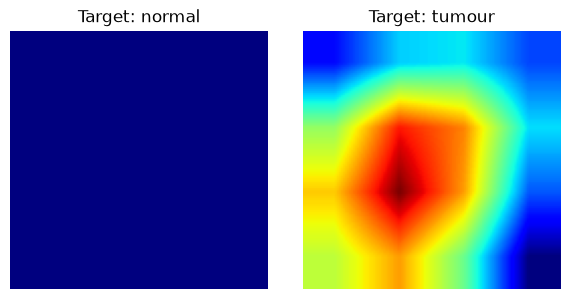

In [15]:
# Additional check: Grad-CAM for both target classes

x01 = to01(xte_s[jt])
xin = normalize(x01).unsqueeze(0).to(device)

fig, ax = plt.subplots(1, 2, figsize=(6, 3))

for target in (0, 1):
    heat = cam_clean(
        x=xin,
        class_idx=target
    ).squeeze().detach().cpu().numpy()

    ax[target].imshow(heat, cmap="jet", vmin=0, vmax=1)
    ax[target].set_title(f"Target: {class_names[target]}")
    ax[target].axis("off")

plt.tight_layout()
plt.show()

## 11 · The skeptic's checklist

**1. Is the heat on plausible morphology or on an artifact?**

Compare the clean and confounded Grad-CAM maps. Does the clean model highlight tissue morphology? Does the confounded model shift its attention toward the synthetic scanner patch?

**2. Does the explanation change sensibly with the target class?**

Compare the explanations for tumour and normal predictions. The target-class comparison should be interpreted alongside the model's predicted probabilities and tissue morphology.

**3. Does occlusion agree with Grad-CAM?**

Compare the spatial patterns and the quantified artifact-attention shares. Agreement is stronger evidence than either visualization alone, but disagreement should also be reported.

**4. Would the highlighted features survive a different scanner or acquisition workflow?**

A model relying on a scanner-specific patch would be vulnerable to changes in acquisition conditions. Removing the patch or encountering images from a different scanner could reduce performance.

**5. Would a clean model react the same way?**

Compare the clean and confounded models using the same artifact-injected test images. The reliance-test difference, normal-to-tumour flip-rate gap, and artifact-attention differences determine whether the results support artifact-specific shortcut learning.

**Verdict:** [Complete after examining the numerical results. State whether the shortcut was learned, partially learned, or not demonstrated.]

## Final summary: Scanner-related shortcut learning

This experiment compared a clean pretrained DenseNet121 classifier with a second model trained on tumour images containing a synthetic scanner calibration patch.

The evaluation included validation and test accuracy, Grad-CAM, occlusion sensitivity, tumour recall with and without the artifact, normal-tile prediction flips, and an independent clean-model control.

**Key results:**

- Clean validation accuracy: **95.8%**
- Clean test accuracy: **93.0%**
- Confounded validation accuracy: **100.0%**
- Confounded tumour recall with patch: **99.7%**
- Confounded tumour recall without patch: **39.3%**
- Normal-to-tumour flip rate, clean model: **2.7%**
- Normal-to-tumour flip rate, confounded model: **84.7%**
- Grad-CAM artifact-attention share: **16.5% (confounded) vs. 4.7% (clean)**
- Occlusion artifact-attention share: **52.3% (confounded) vs. 9.1% (clean)**

**Final verdict:** The confounded model learned a non-biological shortcut. Removing the patch reduced tumour recall by 60.3 percentage points, while the clean model showed minimal sensitivity to the same artifact. The flip test, Grad-CAM, and occlusion results further supported artifact reliance despite perfect validation accuracy.

**Clinical deployment:** Before clinical use, the model would require independent patient- and site-level validation, testing across staining and scanner conditions, and evaluation of potential shortcuts and clinically relevant errors. High validation accuracy alone is insufficient to establish model reliability.